In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error


# 1. Define project data columns
columns = [
    "date",
    "weekday",
    "hour_start",
    "incoming_requests"
]

# 2. Create an empty dataset
df = pd.DataFrame(columns=columns)

# 3. Define the output location
file_path = Path("../data/raw/hourly_patient_requests.csv")

# 4. Save the CSV file
df.to_csv(file_path, index=False)

# 5. Display confirmation
print("Dataset template created successfully!")
print("\nDataset structure:")
print(df)

print("\nFile saved at:", file_path.resolve())


Dataset template created successfully!

Dataset structure:
Empty DataFrame
Columns: [date, weekday, hour_start, incoming_requests]
Index: []

File saved at: C:\Users\Admin\Desktop\healthcare-telemedicine-workforce-planning\data\raw\hourly_patient_requests.csv


In [2]:
# 1. Reproducible random numbers
np.random.seed(42)

# 2. Generate six months of dates
dates = pd.date_range(
    start="2025-01-01",
    end="2025-06-30",
    freq="D"
)

# 3. Weekday demand factors
weekday_factors = {
    "Saturday": 1.00,
    "Sunday": 1.08,
    "Monday": 1.12,
    "Tuesday": 1.15,
    "Wednesday": 1.12,
    "Thursday": 1.05,
    "Friday": 0.65
}

# 4. Hourly demand patterns
hour_factors = {
    0: 0.50,
    1: 0.25,
    2: 0.20,
    3: 0.18,
    4: 0.18,
    5: 0.25,
    6: 0.40,
    7: 0.60,
    8: 0.80,
    9: 0.90,
    10: 1.10,
    11: 1.60,
    12: 1.80,
    13: 1.75,
    14: 1.60,
    15: 1.20,
    16: 1.00,
    17: 1.10,
    18: 1.50,
    19: 1.70,
    20: 1.75,
    21: 1.55,
    22: 0.90,
    23: 0.65
}

# 5. Generate hourly patient requests
records = []

for date in dates:
    weekday = date.day_name()

    for hour in range(24):

        base_calls = 8

        monthly_growth = 1 + (
            (date.month - 1) * 0.01
        )

        expected_calls = (
            base_calls
            * weekday_factors[weekday]
            * hour_factors[hour]
            * monthly_growth
        )

        incoming_requests = np.random.poisson(
            expected_calls
        )

        records.append({
            "date": date.strftime("%Y-%m-%d"),
            "weekday": weekday,
            "hour_start": f"{hour:02d}:00",
            "incoming_requests": incoming_requests
        })

# 6. Create DataFrame
df = pd.DataFrame(records)

# 7. Save simulated data
file_path = Path(
    "../data/raw/hourly_patient_requests.csv"
)

df.to_csv(file_path, index=False)

# 8. Display results
print("Simulated dataset created successfully!")

print("\nFirst 10 records:")
print(df.head(10))

print("\nDataset information:")
print("Total records:", len(df))
print("Total dates:", df["date"].nunique())
print("Total patient requests:", df["incoming_requests"].sum())

print("\nFile saved at:")
print(file_path.resolve())


Simulated dataset created successfully!

First 10 records:
         date    weekday hour_start  incoming_requests
0  2025-01-01  Wednesday      00:00                  5
1  2025-01-01  Wednesday      01:00                  0
2  2025-01-01  Wednesday      02:00                  3
3  2025-01-01  Wednesday      03:00                  2
4  2025-01-01  Wednesday      04:00                  0
5  2025-01-01  Wednesday      05:00                  1
6  2025-01-01  Wednesday      06:00                  4
7  2025-01-01  Wednesday      07:00                  5
8  2025-01-01  Wednesday      08:00                  4
9  2025-01-01  Wednesday      09:00                  9

Dataset information:
Total records: 4344
Total dates: 181
Total patient requests: 35729

File saved at:
C:\Users\Admin\Desktop\healthcare-telemedicine-workforce-planning\data\raw\hourly_patient_requests.csv


In [3]:
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())

print("\nHourly demand summary:")
print(df["incoming_requests"].describe())

<class 'pandas.DataFrame'>
RangeIndex: 4344 entries, 0 to 4343
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   date               4344 non-null   str  
 1   weekday            4344 non-null   str  
 2   hour_start         4344 non-null   str  
 3   incoming_requests  4344 non-null   int64
dtypes: int64(1), str(3)
memory usage: 229.8 KB
None

Missing values:
date                 0
weekday              0
hour_start           0
incoming_requests    0
dtype: int64

Hourly demand summary:
count    4344.000000
mean        8.224908
std         5.706363
min         0.000000
25%         3.000000
50%         8.000000
75%        12.000000
max        29.000000
Name: incoming_requests, dtype: float64


In [4]:
# Step 5: Calculate average hourly demand by weekday

# Define the weekday order used in the original mHealth planning process
weekday_order = [
    "Saturday",
    "Sunday",
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday"
]

# Calculate average requests for each weekday and hour
weekday_hourly_avg = (
    df.groupby(["weekday", "hour_start"])["incoming_requests"]
    .mean()
    .reset_index()
)

# Apply the custom weekday order
weekday_hourly_avg["weekday"] = pd.Categorical(
    weekday_hourly_avg["weekday"],
    categories=weekday_order,
    ordered=True
)

# Sort the results
weekday_hourly_avg = weekday_hourly_avg.sort_values(
    ["weekday", "hour_start"]
).reset_index(drop=True)

# Display results
print("Average hourly demand calculated successfully!")

print("\nFirst 15 rows:")
print(weekday_hourly_avg.head(15))

print("\nTotal weekday-hour combinations:")
print(len(weekday_hourly_avg))

Average hourly demand calculated successfully!

First 15 rows:
     weekday hour_start  incoming_requests
0   Saturday      00:00           4.230769
1   Saturday      01:00           1.730769
2   Saturday      02:00           1.692308
3   Saturday      03:00           1.269231
4   Saturday      04:00           1.500000
5   Saturday      05:00           2.076923
6   Saturday      06:00           3.269231
7   Saturday      07:00           5.192308
8   Saturday      08:00           6.692308
9   Saturday      09:00           7.076923
10  Saturday      10:00           8.769231
11  Saturday      11:00          12.500000
12  Saturday      12:00          14.884615
13  Saturday      13:00          14.192308
14  Saturday      14:00          12.884615

Total weekday-hour combinations:
168


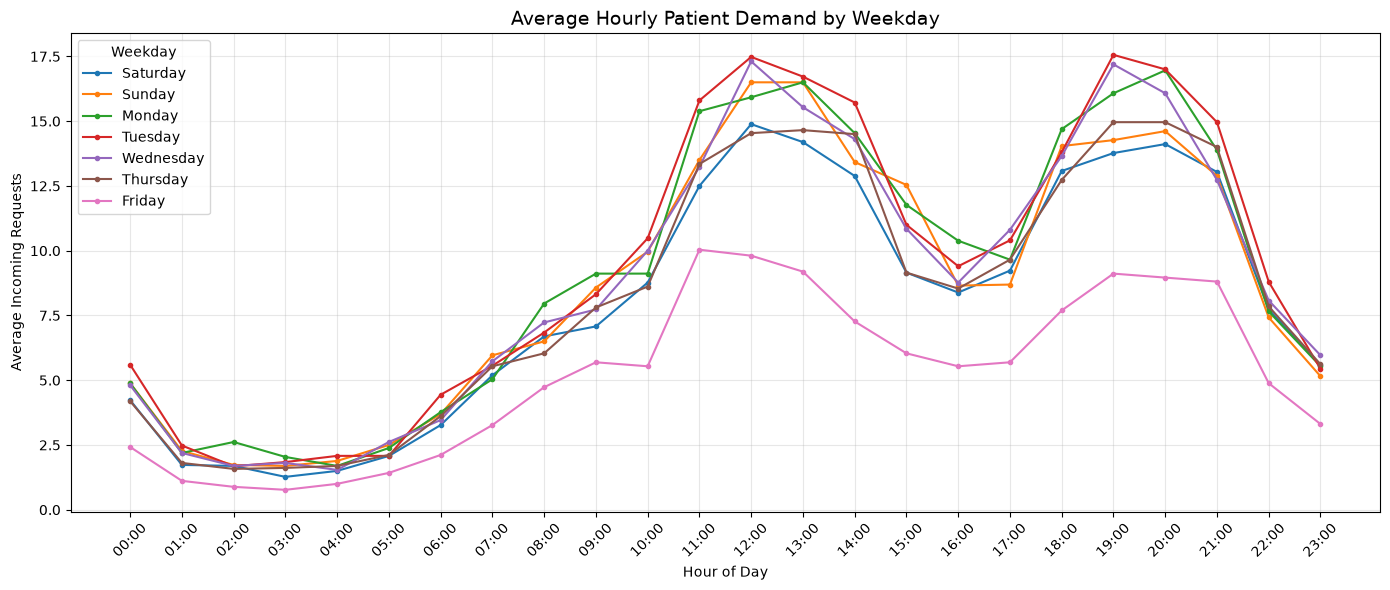

In [5]:
# Step 6: Visualize hourly patient demand patterns

import matplotlib.pyplot as plt

# Prepare data for the chart
demand_chart = weekday_hourly_avg.pivot(
    index="hour_start",
    columns="weekday",
    values="incoming_requests"
)

# Arrange weekdays in the original mHealth order
demand_chart = demand_chart[weekday_order]

# Create line chart
plt.figure(figsize=(14, 6))

for day in weekday_order:
    plt.plot(
        demand_chart.index,
        demand_chart[day],
        marker="o",
        markersize=3,
        label=day
    )

plt.title(
    "Average Hourly Patient Demand by Weekday",
    fontsize=14
)

plt.xlabel("Hour of Day")
plt.ylabel("Average Incoming Requests")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend(title="Weekday")

plt.tight_layout()
plt.show()

In [6]:
# Step 7: Categorize hourly demand into shifts

def assign_shift(hour):
    if 8 <= hour < 14:
        return "Morning"
    elif 14 <= hour < 22:
        return "Evening"
    else:
        return "Night"


# Create a copy of the hourly demand table
shift_demand = weekday_hourly_avg.copy()

# Extract numerical hour
shift_demand["hour"] = (
    shift_demand["hour_start"].str[:2].astype(int)
)

# Assign shifts
shift_demand["shift"] = (
    shift_demand["hour"].apply(assign_shift)
)

# Calculate average hourly demand by weekday and shift
shift_summary = (
    shift_demand.groupby(
        ["weekday", "shift"],
        observed=False
    )["incoming_requests"]
    .mean()
    .reset_index()
)

print("Shift-wise demand calculated successfully!")

print(shift_summary)

Shift-wise demand calculated successfully!
      weekday    shift  incoming_requests
0    Saturday  Evening          11.706731
1    Saturday  Morning          10.685897
2    Saturday    Night           3.426923
3      Sunday  Evening          12.389423
4      Sunday  Morning          11.923077
5      Sunday    Night           3.719231
6      Monday  Evening          13.495192
7      Monday  Morning          12.333333
8      Monday    Night           3.780769
9     Tuesday  Evening          13.730000
10    Tuesday  Morning          12.606667
11    Tuesday    Night           4.000000
12  Wednesday  Evening          13.048077
13  Wednesday  Morning          11.839744
14  Wednesday    Night           3.788462
15   Thursday  Evening          12.312500
16   Thursday  Morning          10.833333
17   Thursday    Night           3.561538
18     Friday  Evening           7.389423
19     Friday  Morning           7.500000
20     Friday    Night           2.119231


In [7]:
# Step 8: Define consultation handling time

# Initial modelling assumptions (minutes)
minimum_recommended_aht = 5
typical_aht_low = 10
typical_aht_high = 15

# Initial baseline assumption
average_handling_time = 12.5

# Existing Day Planner settings
shrinkage = 0.20
service_level = 0.95
reporting_period = 60

print("AHT and staffing parameters defined!")

print("Minimum recommended AHT:", minimum_recommended_aht, "minutes")
print("Typical AHT range:", typical_aht_low, "-", typical_aht_high, "minutes")
print("Baseline AHT:", average_handling_time, "minutes")
print("Shrinkage:", shrinkage * 100, "%")
print("Service level reference:", service_level * 100, "%")

AHT and staffing parameters defined!
Minimum recommended AHT: 5 minutes
Typical AHT range: 10 - 15 minutes
Baseline AHT: 12.5 minutes
Shrinkage: 20.0 %
Service level reference: 95.0 %


In [8]:
# Callback service target

callback_target_minutes = 30

print("Callback target:", callback_target_minutes, "minutes")
print("Average handling time:", average_handling_time, "minutes")
print("Shrinkage:", shrinkage * 100, "%")

Callback target: 30 minutes
Average handling time: 12.5 minutes
Shrinkage: 20.0 %


In [9]:
# Step 9: Calculate preliminary hourly doctor requirements
# Calculate workload in minutes
weekday_hourly_avg["workload_minutes"] = (
    weekday_hourly_avg["incoming_requests"]
    * average_handling_time
)

# Calculate available working minutes per doctor per hour
available_minutes = reporting_period * (1 - shrinkage)

# Calculate required doctors and round up
weekday_hourly_avg["doctors_required"] = np.ceil(
    weekday_hourly_avg["workload_minutes"]
    / available_minutes
).astype(int)

# Display results
print("Hourly doctor requirements calculated!")

print("\nFirst 20 records:")
print(
    weekday_hourly_avg[
        ["weekday", "hour_start", "incoming_requests",
         "workload_minutes", "doctors_required"]
    ].head(20)
)

print("\nTotal weekday-hour combinations:")
print(len(weekday_hourly_avg))

print("\nMaximum preliminary doctor requirement:")
print(weekday_hourly_avg["doctors_required"].max())

Hourly doctor requirements calculated!

First 20 records:
     weekday hour_start  incoming_requests  workload_minutes  doctors_required
0   Saturday      00:00           4.230769         52.884615                 2
1   Saturday      01:00           1.730769         21.634615                 1
2   Saturday      02:00           1.692308         21.153846                 1
3   Saturday      03:00           1.269231         15.865385                 1
4   Saturday      04:00           1.500000         18.750000                 1
5   Saturday      05:00           2.076923         25.961538                 1
6   Saturday      06:00           3.269231         40.865385                 1
7   Saturday      07:00           5.192308         64.903846                 2
8   Saturday      08:00           6.692308         83.653846                 2
9   Saturday      09:00           7.076923         88.461538                 2
10  Saturday      10:00           8.769231        109.615385             

In [10]:
# Add hour and shift columns to the staffing table

weekday_hourly_avg["hour"] = (
    weekday_hourly_avg["hour_start"].str[:2].astype(int)
)

def assign_shift(hour):
    if 8 <= hour < 14:
        return "Morning"
    elif 14 <= hour < 22:
        return "Evening"
    else:
        return "Night"

weekday_hourly_avg["shift"] = (
    weekday_hourly_avg["hour"].apply(assign_shift)
)

print("Shift column added successfully!")

print(
    weekday_hourly_avg[
        ["weekday", "hour_start", "shift", "doctors_required"]
    ].head(15)
)

Shift column added successfully!
     weekday hour_start    shift  doctors_required
0   Saturday      00:00    Night                 2
1   Saturday      01:00    Night                 1
2   Saturday      02:00    Night                 1
3   Saturday      03:00    Night                 1
4   Saturday      04:00    Night                 1
5   Saturday      05:00    Night                 1
6   Saturday      06:00    Night                 1
7   Saturday      07:00    Night                 2
8   Saturday      08:00  Morning                 2
9   Saturday      09:00  Morning                 2
10  Saturday      10:00  Morning                 3
11  Saturday      11:00  Morning                 4
12  Saturday      12:00  Morning                 4
13  Saturday      13:00  Morning                 4
14  Saturday      14:00  Evening                 4


In [11]:
shift_staffing = (
    weekday_hourly_avg.groupby(
        ["weekday", "shift"],
        observed=False
    )["doctors_required"]
    .agg(["mean", "max"])
    .reset_index()
)

shift_staffing["mean"] = shift_staffing["mean"].round(2)

print("Shift-level staffing calculated successfully!")
print(shift_staffing.to_string(index=False))

Shift-level staffing calculated successfully!
  weekday   shift  mean  max
 Saturday Evening  3.62    4
 Saturday Morning  3.17    4
 Saturday   Night  1.50    3
   Sunday Evening  3.75    4
   Sunday Morning  3.67    5
   Sunday   Night  1.40    2
   Monday Evening  4.00    5
   Monday Morning  4.00    5
   Monday   Night  1.40    2
  Tuesday Evening  4.00    5
  Tuesday Morning  3.83    5
  Tuesday   Night  1.60    3
Wednesday Evening  3.88    5
Wednesday Morning  3.67    5
Wednesday   Night  1.50    3
 Thursday Evening  3.62    4
 Thursday Morning  3.33    4
 Thursday   Night  1.50    3
   Friday Evening  2.50    3
   Friday Morning  2.50    3
   Friday   Night  1.10    2


In [12]:
# Step 11: Create weekly shift staffing plan

weekday_order = [
    "Saturday", "Sunday", "Monday", "Tuesday",
    "Wednesday", "Thursday", "Friday"
]

shift_order = ["Morning", "Evening", "Night"]

# Create staffing matrix using peak hourly requirements
weekly_staffing_plan = (
    shift_staffing.pivot(
        index="weekday",
        columns="shift",
        values="max"
    )
    .reindex(index=weekday_order, columns=shift_order)
    .astype(int)
)

print("Weekly staffing plan created successfully!")

print(weekly_staffing_plan)

print("\nTotal planned doctor-shift assignments per week:")
print(weekly_staffing_plan.sum().sum())

Weekly staffing plan created successfully!
shift      Morning  Evening  Night
weekday                           
Saturday         4        4      3
Sunday           5        4      2
Monday           5        5      2
Tuesday          5        5      3
Wednesday        5        5      3
Thursday         4        4      3
Friday           3        3      2

Total planned doctor-shift assignments per week:
79


In [13]:
# Correct shift-day assignment for overnight shifts

weekday_order = [
    "Saturday", "Sunday", "Monday", "Tuesday",
    "Wednesday", "Thursday", "Friday"
]

def get_shift_day(row):
    day = str(row["weekday"])
    hour = row["hour"]

    if hour < 8:
        current_index = weekday_order.index(day)
        previous_index = (current_index - 1) % 7
        return weekday_order[previous_index]

    return day


weekday_hourly_avg["shift_day"] = (
    weekday_hourly_avg.apply(get_shift_day, axis=1)
)

# Recalculate shift-level staffing
shift_staffing = (
    weekday_hourly_avg.groupby(
        ["shift_day", "shift"],
        observed=False
    )["doctors_required"]
    .agg(["mean", "max"])
    .reset_index()
)

shift_staffing["mean"] = shift_staffing["mean"].round(2)

# Create corrected weekly staffing matrix
shift_order = ["Morning", "Evening", "Night"]

weekly_staffing_plan = (
    shift_staffing.pivot(
        index="shift_day",
        columns="shift",
        values="max"
    )
    .reindex(index=weekday_order, columns=shift_order)
    .astype(int)
)

print("Corrected weekly staffing plan:")
print(weekly_staffing_plan)

print("\nTotal doctor-shift assignments:")
print(weekly_staffing_plan.sum().sum())

Corrected weekly staffing plan:
shift      Morning  Evening  Night
shift_day                         
Saturday         4        4      3
Sunday           5        4      2
Monday           5        5      2
Tuesday          5        5      3
Wednesday        5        5      3
Thursday         4        4      3
Friday           3        3      2

Total doctor-shift assignments:
79


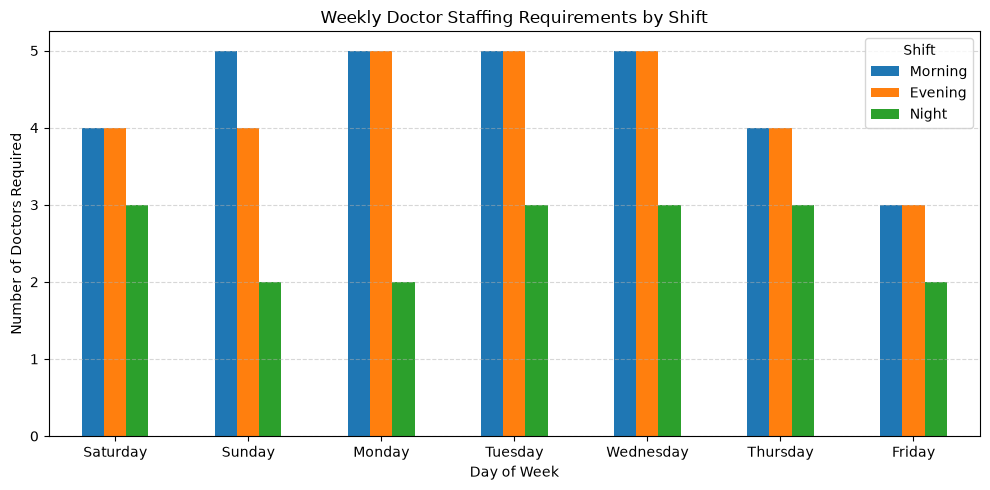

In [14]:
weekly_staffing_plan.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Weekly Doctor Staffing Requirements by Shift")
plt.xlabel("Day of Week")
plt.ylabel("Number of Doctors Required")
plt.xticks(rotation=0)
plt.legend(title="Shift")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [15]:
weekly_staffing_plan.to_csv(
    "../data/processed/weekly_staffing_plan.csv"
)

print("Weekly staffing plan saved successfully!")

Weekly staffing plan saved successfully!


In [16]:
# Load the original dataset
raw_data = pd.read_csv(
    "../data/raw/hourly_patient_requests.csv"
)

# Convert date column
raw_data["date"] = pd.to_datetime(raw_data["date"])

# Extract month
raw_data["month"] = raw_data["date"].dt.to_period("M")

# Calculate monthly demand
monthly_demand = (
    raw_data.groupby("month")["incoming_requests"]
    .sum()
    .reset_index()
)

monthly_demand["month"] = monthly_demand["month"].astype(str)

print("Monthly Patient Demand:")
print(monthly_demand)

Monthly Patient Demand:
     month  incoming_requests
0  2025-01               5906
1  2025-02               5400
2  2025-03               6149
3  2025-04               5903
4  2025-05               6129
5  2025-06               6242


In [17]:
# Calculate total requests per day
daily_demand = (
    raw_data.groupby("date")["incoming_requests"]
    .sum()
    .reset_index()
)

# Extract month
daily_demand["month"] = daily_demand["date"].dt.to_period("M")

# Calculate average daily demand
monthly_daily_avg = (
    daily_demand.groupby("month")["incoming_requests"]
    .mean()
    .reset_index()
)

monthly_daily_avg["incoming_requests"] = (
    monthly_daily_avg["incoming_requests"].round(2)
)

monthly_daily_avg["month"] = (
    monthly_daily_avg["month"].astype(str)
)

print("Average Daily Patient Demand by Month:")
print(monthly_daily_avg)

Average Daily Patient Demand by Month:
     month  incoming_requests
0  2025-01             190.52
1  2025-02             192.86
2  2025-03             198.35
3  2025-04             196.77
4  2025-05             197.71
5  2025-06             208.07


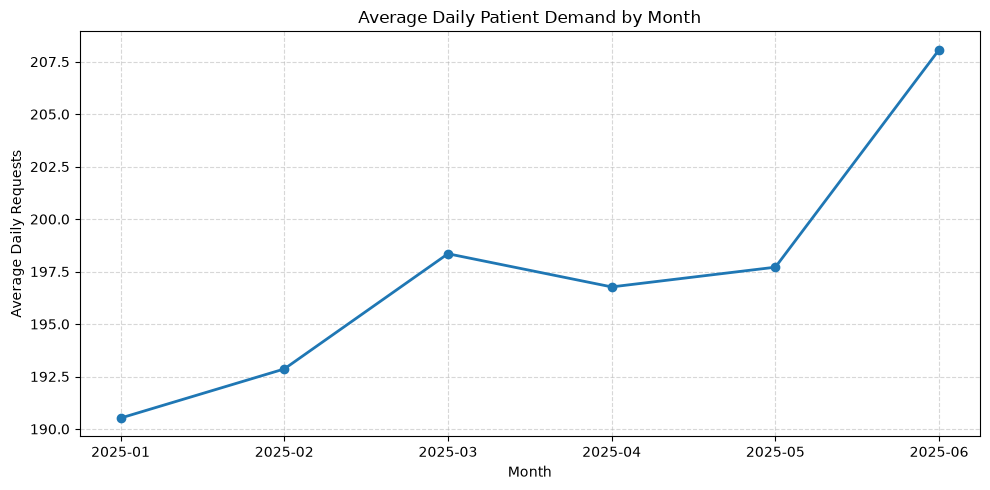

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_daily_avg["month"],
    monthly_daily_avg["incoming_requests"],
    marker="o",
    linewidth=2
)

plt.title("Average Daily Patient Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Requests")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [19]:
forecast_data = monthly_daily_avg.copy()

forecast_data["month_number"] = range(
    1, len(forecast_data) + 1
)

print("Data prepared for forecasting:")
print(forecast_data)

Data prepared for forecasting:
     month  incoming_requests  month_number
0  2025-01             190.52             1
1  2025-02             192.86             2
2  2025-03             198.35             3
3  2025-04             196.77             4
4  2025-05             197.71             5
5  2025-06             208.07             6


In [20]:
# Prepare input and target variables
X = forecast_data[["month_number"]]
y = forecast_data["incoming_requests"]

# Train the model
model = LinearRegression()
model.fit(X, y)

# Display model information
print("Model trained successfully!")
print("Slope:", round(model.coef_[0], 2))
print("Intercept:", round(model.intercept_, 2))

Model trained successfully!
Slope: 2.88
Intercept: 187.31


In [21]:
july_data = pd.DataFrame({
    "month_number": [7]
})

july_forecast = model.predict(july_data)

print(
    "Forecasted average daily requests for July 2025:",
    round(july_forecast[0], 2)
)

Forecasted average daily requests for July 2025: 207.45


In [22]:
june_actual = monthly_daily_avg.iloc[-1]["incoming_requests"]

july_predicted = round(july_forecast[0], 2)

change = july_predicted - june_actual
change_percentage = (change / june_actual) * 100

print("June actual daily demand:", june_actual)
print("July forecast daily demand:", july_predicted)
print("Expected increase:", round(change, 2))
print("Expected growth:", round(change_percentage, 2), "%")

June actual daily demand: 208.07
July forecast daily demand: 207.45
Expected increase: -0.62
Expected growth: -0.3 %


In [23]:
# Predict historical values
historical_predictions = model.predict(X)

# Calculate accuracy metrics
mae = mean_absolute_error(y, historical_predictions)
rmse = np.sqrt(mean_squared_error(y, historical_predictions))

print("Model Evaluation:")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

Model Evaluation:
MAE: 2.08
RMSE: 2.53


In [24]:
forecast_results = pd.DataFrame({
    "metric": [
        "June Actual Daily Demand",
        "July Forecast Daily Demand",
        "Expected Change",
        "Expected Growth (%)",
        "MAE",
        "RMSE"
    ],
    "value": [
        june_actual,
        july_predicted,
        round(change, 2),
        round(change_percentage, 2),
        round(mae, 2),
        round(rmse, 2)
    ]
})

forecast_results.to_csv(
    "../data/processed/forecast_results.csv",
    index=False
)

print("Forecast results saved successfully!")

Forecast results saved successfully!


In [25]:
# Extract weekday and hour
raw_data["weekday"] = raw_data["date"].dt.day_name()
raw_data["hour"] = raw_data["hour_start"]

# Define weekday order
weekday_order = [
    "Saturday", "Sunday", "Monday", "Tuesday",
    "Wednesday", "Thursday", "Friday"
]

# Calculate monthly weekday-hour averages
monthly_hourly_avg = (
    raw_data.groupby(
        ["month", "weekday", "hour"],
        observed=False
    )["incoming_requests"]
    .mean()
    .reset_index()
)

# Sort the results
monthly_hourly_avg["weekday"] = pd.Categorical(
    monthly_hourly_avg["weekday"],
    categories=weekday_order,
    ordered=True
)

monthly_hourly_avg = monthly_hourly_avg.sort_values(
    ["month", "weekday", "hour"]
)

print("Monthly weekday-hour demand:")
print(monthly_hourly_avg.head(15))

print("\nTotal records:", len(monthly_hourly_avg))

Monthly weekday-hour demand:
      month   weekday   hour  incoming_requests
48  2025-01  Saturday  00:00               3.00
49  2025-01  Saturday  01:00               1.75
50  2025-01  Saturday  02:00               2.75
51  2025-01  Saturday  03:00               0.50
52  2025-01  Saturday  04:00               2.00
53  2025-01  Saturday  05:00               2.75
54  2025-01  Saturday  06:00               4.25
55  2025-01  Saturday  07:00               5.00
56  2025-01  Saturday  08:00               6.25
57  2025-01  Saturday  09:00               7.50
58  2025-01  Saturday  10:00               9.75
59  2025-01  Saturday  11:00              10.75
60  2025-01  Saturday  12:00              14.75
61  2025-01  Saturday  13:00              10.75
62  2025-01  Saturday  14:00              11.50

Total records: 1008


In [26]:
monthly_hourly_avg.to_csv(
    "../data/processed/monthly_weekday_hourly_demand.csv",
    index=False
)

print("Monthly weekday-hour demand saved successfully!")

Monthly weekday-hour demand saved successfully!


In [27]:
# Compare monthly average demand
monthly_comparison = (
    monthly_hourly_avg.groupby("month")["incoming_requests"]
    .mean()
    .reset_index()
)

monthly_comparison["incoming_requests"] = (
    monthly_comparison["incoming_requests"].round(2)
)

print("Monthly Average Hourly Demand:")
print(monthly_comparison)

Monthly Average Hourly Demand:
     month  incoming_requests
0  2025-01               8.01
1  2025-02               8.04
2  2025-03               8.23
3  2025-04               8.14
4  2025-05               8.37
5  2025-06               8.62


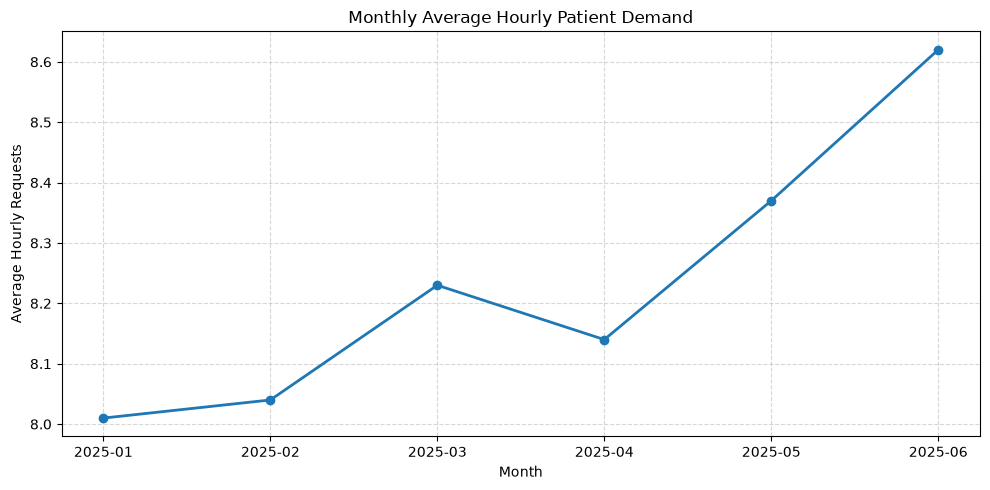

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_comparison["month"].astype(str),
    monthly_comparison["incoming_requests"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Hourly Patient Demand")
plt.xlabel("Month")
plt.ylabel("Average Hourly Requests")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [29]:
june_hourly_demand = (
    monthly_hourly_avg[
        monthly_hourly_avg["month"] == "2025-06"
    ]
    .groupby("hour")["incoming_requests"]
    .mean()
    .reset_index()
    .sort_values("incoming_requests", ascending=False)
)

print("Top 10 busiest hours in June 2025:")
print(june_hourly_demand.head(10).round(2))

Top 10 busiest hours in June 2025:
     hour  incoming_requests
12  12:00              16.00
19  19:00              15.82
13  13:00              15.53
20  20:00              14.51
14  14:00              14.21
11  11:00              14.12
21  21:00              13.50
18  18:00              12.83
17  17:00              10.17
15  15:00               9.69


In [30]:
june_hourly_demand.to_csv(
    "../data/processed/june_busiest_hours.csv",
    index=False
)

print("June busiest-hour analysis saved successfully!")

June busiest-hour analysis saved successfully!


In [31]:
aht_scenarios = [10, 12.5, 15]

sensitivity_results = weekday_hourly_avg[
    ["weekday", "hour_start", "incoming_requests"]
].copy()

for aht in aht_scenarios:
    column_name = f"doctors_AHT_{aht}"

    workload = (
        sensitivity_results["incoming_requests"] * aht
    )

    sensitivity_results[column_name] = np.ceil(
        workload / (60 * (1 - shrinkage))
    ).astype(int)

print("AHT Sensitivity Analysis:")
print(sensitivity_results.head(15))

AHT Sensitivity Analysis:
     weekday hour_start  incoming_requests  doctors_AHT_10  doctors_AHT_12.5  \
0   Saturday      00:00           4.230769               1                 2   
1   Saturday      01:00           1.730769               1                 1   
2   Saturday      02:00           1.692308               1                 1   
3   Saturday      03:00           1.269231               1                 1   
4   Saturday      04:00           1.500000               1                 1   
5   Saturday      05:00           2.076923               1                 1   
6   Saturday      06:00           3.269231               1                 1   
7   Saturday      07:00           5.192308               2                 2   
8   Saturday      08:00           6.692308               2                 2   
9   Saturday      09:00           7.076923               2                 2   
10  Saturday      10:00           8.769231               2                 3   
11  Saturday  

In [32]:
sensitivity_summary = pd.DataFrame({
    "AHT_Minutes": [10, 12.5, 15],
    "Total_Hourly_Requirements": [
        sensitivity_results["doctors_AHT_10"].sum(),
        sensitivity_results["doctors_AHT_12.5"].sum(),
        sensitivity_results["doctors_AHT_15"].sum()
    ],
    "Peak_Doctors_Required": [
        sensitivity_results["doctors_AHT_10"].max(),
        sensitivity_results["doctors_AHT_12.5"].max(),
        sensitivity_results["doctors_AHT_15"].max()
    ]
})

print(sensitivity_summary)

   AHT_Minutes  Total_Hourly_Requirements  Peak_Doctors_Required
0         10.0                        377                      4
1         12.5                        448                      5
2         15.0                        515                      6


In [33]:
baseline_total = sensitivity_summary.loc[
    sensitivity_summary["AHT_Minutes"] == 12.5,
    "Total_Hourly_Requirements"
].iloc[0]

sensitivity_summary["Increase_vs_Baseline_%"] = (
    (sensitivity_summary["Total_Hourly_Requirements"] - baseline_total)
    / baseline_total * 100
).round(2)

print(sensitivity_summary)

   AHT_Minutes  Total_Hourly_Requirements  Peak_Doctors_Required  \
0         10.0                        377                      4   
1         12.5                        448                      5   
2         15.0                        515                      6   

   Increase_vs_Baseline_%  
0                  -15.85  
1                    0.00  
2                   14.96  


In [34]:
sensitivity_summary.to_csv(
    "../data/processed/aht_sensitivity_analysis.csv",
    index=False
)

print("AHT sensitivity analysis saved successfully!")

AHT sensitivity analysis saved successfully!


In [35]:
weekday_sensitivity = (
    sensitivity_results.groupby("weekday")[
        [
            "doctors_AHT_10",
            "doctors_AHT_12.5",
            "doctors_AHT_15"
        ]
    ]
    .sum()
    .reindex(weekday_order)
)

print("Weekday Staffing Comparison:")
print(weekday_sensitivity)

Weekday Staffing Comparison:
           doctors_AHT_10  doctors_AHT_12.5  doctors_AHT_15
weekday                                                    
Saturday               50                63              73
Sunday                 55                66              78
Monday                 60                70              80
Tuesday                60                71              81
Wednesday              57                68              79
Thursday               55                64              73
Friday                 40                46              51


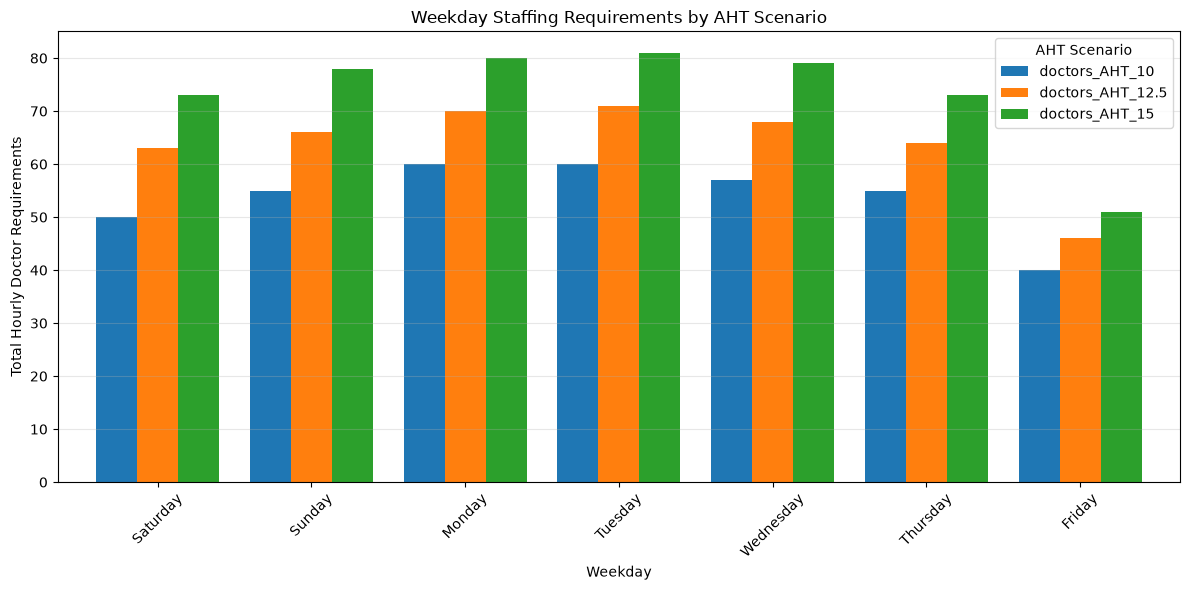

In [36]:
weekday_sensitivity.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Weekday Staffing Requirements by AHT Scenario")
plt.xlabel("Weekday")
plt.ylabel("Total Hourly Doctor Requirements")
plt.xticks(rotation=45)
plt.legend(title="AHT Scenario")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
print("Final Weekly Staffing Recommendation:")
print(weekly_staffing_plan)

print("\nTotal Doctor-Shift Assignments:")
print(weekly_staffing_plan.sum().sum())

Final Weekly Staffing Recommendation:
shift      Morning  Evening  Night
shift_day                         
Saturday         4        4      3
Sunday           5        4      2
Monday           5        5      2
Tuesday          5        5      3
Wednesday        5        5      3
Thursday         4        4      3
Friday           3        3      2

Total Doctor-Shift Assignments:
79


In [38]:
final_summary = pd.DataFrame({
    "Metric": [
        "Total Simulated Requests",
        "Dataset Records",
        "Weekday-Hour Combinations",
        "Baseline AHT (minutes)",
        "Shrinkage (%)",
        "Peak Hourly Doctor Requirement",
        "Weekly Doctor-Shift Assignments",
        "July Forecast Daily Demand",
        "AHT 10-Minute Total Requirements",
        "AHT 12.5-Minute Total Requirements",
        "AHT 15-Minute Total Requirements"
    ],
    "Result": [
        35729,
        4344,
        168,
        12.5,
        20,
        5,
        79,
        207.45,
        377,
        448,
        515
    ]
})

final_summary.to_csv(
    "../outputs/final_project_summary.csv",
    index=False
)

print(final_summary)
print("\nFinal project summary saved successfully!")

                                Metric    Result
0             Total Simulated Requests  35729.00
1                      Dataset Records   4344.00
2            Weekday-Hour Combinations    168.00
3               Baseline AHT (minutes)     12.50
4                        Shrinkage (%)     20.00
5       Peak Hourly Doctor Requirement      5.00
6      Weekly Doctor-Shift Assignments     79.00
7           July Forecast Daily Demand    207.45
8     AHT 10-Minute Total Requirements    377.00
9   AHT 12.5-Minute Total Requirements    448.00
10    AHT 15-Minute Total Requirements    515.00

Final project summary saved successfully!
